# V2 — Leakage-Controlled 1–7 Day Berlin Temperature Forecasting

## Purpose
The central experimental question is:

> **How do persistence baselines, Prophet, Bidirectional LSTM, and Transformer models perform for direct 1–7 day ahead daily mean temperature forecasting in Berlin when all models are evaluated under the same information constraints?**

### Major methodological changes from V1

1. **Direct 7-day forecasting:** the neural networks predict all seven future temperatures simultaneously instead of being trained only for one-step prediction and then recursively rolled forward.
2. **Strict chronological splitting:** train / validation / test are separated in time.
3. **No scaling leakage:** scalers are fitted only on data available before the relevant evaluation period.
4. **No future meteorological regressors:** Prophet is evaluated without using future humidity, radiation, wind, or precipitation that would not be known at forecast time.
5. **Naive baselines:** persistence and weekly seasonal-naive forecasts are included.
6. **MAPE removed:** temperature can be zero or negative, so MAPE is not an appropriate primary metric.
7. **Horizon-specific metrics:** MAE, RMSE, R², sMAPE and MASE are reported separately for horizons 1–7.
8. **Rolling-origin final evaluation:** several 7-day forecast origins are evaluated using only information available at each origin.
9. **Hyperparameter tuning:** deep-learning tuning uses the validation period only; the test period is never used for model selection.
10. **Reproducibility:** fixed random seed, explicit dates, saved configuration and saved result tables.

> **Important:** Run the notebook from top to bottom. Do not change the test period after seeing test results.

# 1. Experimental Design

### Data

- Location: Berlin, Germany
- Coordinates: 52.52°N, 13.405°E
- Source: Open-Meteo historical API / ERA5
- Daily observations
- Default history: 2021-01-01 through 2026-08-31
- Target: daily mean 2-m air temperature (`temp_mean`)

### Candidate models

**Baselines**
- Persistence: tomorrow and the following six days equal the last observed temperature.
- Weekly seasonal naive: each future day uses the temperature seven days earlier.

**Statistical**
- Prophet using historical target values and calendar seasonality only.

**Deep learning**
- Bidirectional LSTM
- Transformer encoder

### Forecasting strategy

All neural models use:

**30 observed days → 7 future daily mean temperatures**

No model receives future observed weather variables during evaluation.

### Final evaluation

The final test uses multiple forecast origins. At each origin:

1. Only observations available up to that date are used.
2. Deep-learning scalers are fitted using only observations available up to that date.
3. Deep-learning models are trained using observations available up to that date and the previously selected hyperparameters.
4. Prophet is fitted only to observations available up to that date.
5. Each model predicts the next seven days.
6. Predictions are compared against the actual next seven days.

This is the core V2 evaluation protocol.

In [2]:
# 2. Installation
# Run this cell once in the environment used for the thesis.

%pip install -q numpy pandas matplotlib scikit-learn tensorflow keras-tuner prophet requests


/Users/dev/.venvs/datascience/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
# 3. Imports and reproducibility

import os
import json
import random
import logging
import warnings
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import (
    Input, Dense, Dropout, LSTM, Bidirectional,
    LayerNormalization, MultiHeadAttention,
    GlobalAveragePooling1D, Add
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import keras_tuner as kt
from prophet import Prophet

warnings.filterwarnings("ignore")
logging.getLogger("prophet").setLevel(logging.WARNING)
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


TensorFlow: 2.21.0
NumPy: 2.5.3
Pandas: 3.0.6


In [6]:
# 4. Configuration

LATITUDE = 52.52
LONGITUDE = 13.405
CITY = "Berlin"

# Keep these dates fixed for the final thesis run.
START_DATE = "2021-01-01"
END_DATE = "2026-08-31"

LOOKBACK = 30
HORIZON = 7

TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

N_ROLLING_ORIGINS = 6

# Tuning controls
RUN_TUNING = True
LSTM_MAX_TRIALS = 8
TRANSFORMER_MAX_TRIALS = 8
TUNER_MAX_EPOCHS = 30

# Final rolling evaluation can be computationally expensive.
RUN_ROLLING_EVALUATION = True

# Optional analyses
RUN_FEATURE_ABLATION = False
RUN_LOOKBACK_ABLATION = False
RUN_LIVE_FORECAST = False

METEO_FEATURES = [
    "temp_max",
    "temp_min",
    "temp_mean",
    "precipitation",
    "wind_speed_max",
    "radiation",
    "evapotranspiration",
    "humidity_max",
    "humidity_min",
    "humidity_mean",
]

TARGET = "temp_mean"

print(json.dumps({
    "city": CITY,
    "coordinates": [LATITUDE, LONGITUDE],
    "start_date": START_DATE,
    "end_date": END_DATE,
    "lookback": LOOKBACK,
    "forecast_horizon": HORIZON,
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VALIDATION_RATIO,
    "test_ratio": TEST_RATIO,
    "rolling_origins": N_ROLLING_ORIGINS,
}, indent=2))


{
  "city": "Berlin",
  "coordinates": [
    52.52,
    13.405
  ],
  "start_date": "2021-01-01",
  "end_date": "2026-08-31",
  "lookback": 30,
  "forecast_horizon": 7,
  "train_ratio": 0.7,
  "validation_ratio": 0.15,
  "test_ratio": 0.15,
  "rolling_origins": 6
}


# 5. Data Collection

The historical period is explicitly fixed so that the final thesis results can be reproduced.

The API data are treated as historical meteorological observations/reanalysis data. The forecasting experiment itself does not use future meteorological covariates.

In [7]:
def fetch_open_meteo_history(
    latitude=LATITUDE,
    longitude=LONGITUDE,
    start_date=START_DATE,
    end_date=END_DATE,
):
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "temperature_2m_mean",
            "precipitation_sum",
            "windspeed_10m_max",
            "shortwave_radiation_sum",
            "et0_fao_evapotranspiration",
            "relative_humidity_2m_max",
            "relative_humidity_2m_min",
            "relative_humidity_2m_mean",
        ],
        "timezone": "Europe/Berlin",
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    payload = response.json()

    daily = payload["daily"]

    frame = pd.DataFrame({
        "date": pd.to_datetime(daily["time"]),
        "temp_max": daily["temperature_2m_max"],
        "temp_min": daily["temperature_2m_min"],
        "temp_mean": daily["temperature_2m_mean"],
        "precipitation": daily["precipitation_sum"],
        "wind_speed_max": daily["windspeed_10m_max"],
        "radiation": daily["shortwave_radiation_sum"],
        "evapotranspiration": daily["et0_fao_evapotranspiration"],
        "humidity_max": daily["relative_humidity_2m_max"],
        "humidity_min": daily["relative_humidity_2m_min"],
        "humidity_mean": daily["relative_humidity_2m_mean"],
    })

    frame = frame.drop_duplicates("date").sort_values("date").set_index("date")
    return frame


df = fetch_open_meteo_history()

print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate dates:", df.index.duplicated().sum())


Shape: (2069, 10)
Date range: 2021-01-01 to 2026-08-31

Missing values:
temp_max              0
temp_min              0
temp_mean             0
precipitation         0
wind_speed_max        0
radiation             0
evapotranspiration    0
humidity_max          0
humidity_min          0
humidity_mean         0
dtype: int64

Duplicate dates: 0


In [8]:
# 6. Data quality checks and leakage-safe missing-value handling

assert df.index.is_monotonic_increasing
assert df.index.is_unique

# Forward fill only: never use a future observation to fill an earlier missing value.
df_clean = df[METEO_FEATURES].ffill()

# If the very beginning contains missing values, drop them rather than backward-fill.
df_clean = df_clean.dropna()

print("Remaining missing values:", int(df_clean.isna().sum().sum()))
print("Final shape:", df_clean.shape)

# Basic descriptive statistics
display(df_clean.describe().T.round(3))


Remaining missing values: 0
Final shape: (2069, 10)


,count,mean,std,min,25%,50%,75%,max
temp_max,2069.0,14.947,8.875,-7.40,7.90,15.1,21.90,39.80
temp_min,2069.0,7.044,7.083,-15.00,1.60,7.0,13.00,27.50
temp_mean,2069.0,10.947,7.861,-10.30,4.90,10.7,17.70,32.90
precipitation,2069.0,1.738,3.570,0.00,0.00,0.2,1.90,44.30
wind_speed_max,2069.0,18.508,6.658,4.60,13.50,17.5,22.50,49.70
radiation,2069.0,11.925,8.188,0.29,4.01,11.3,18.76,29.57
evapotranspiration,2069.0,2.331,1.780,0.11,0.73,1.9,3.71,8.23
humidity_max,2069.0,89.867,8.766,48.00,87.00,92.0,96.00,100.00
humidity_min,2069.0,56.787,18.125,11.00,42.00,56.0,71.00,96.00
humidity_mean,2069.0,74.340,13.505,28.00,65.00,76.0,85.00,99.00


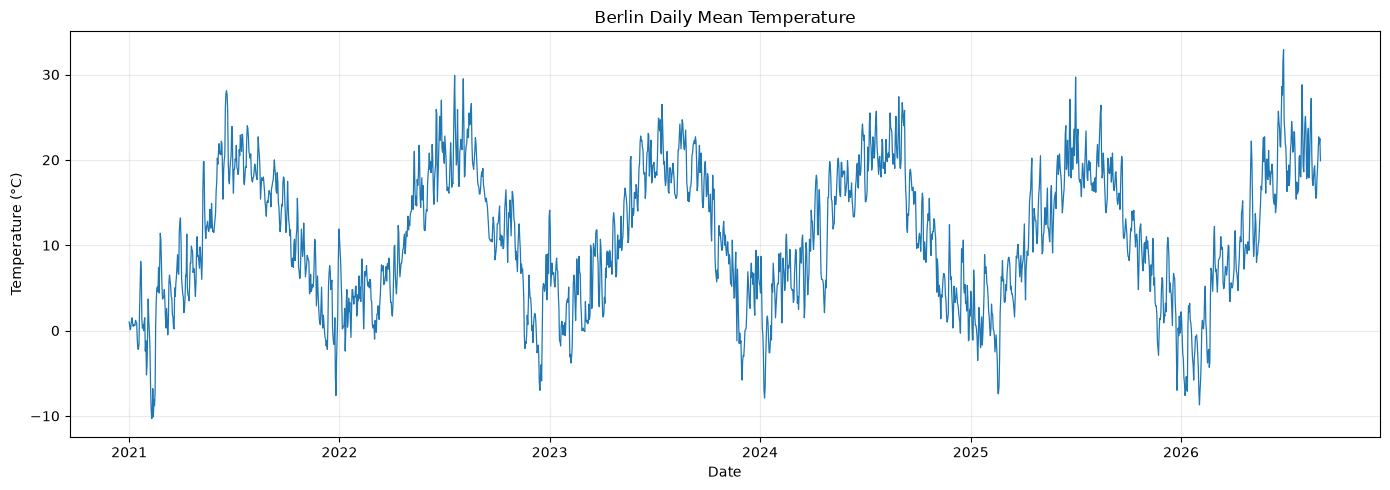

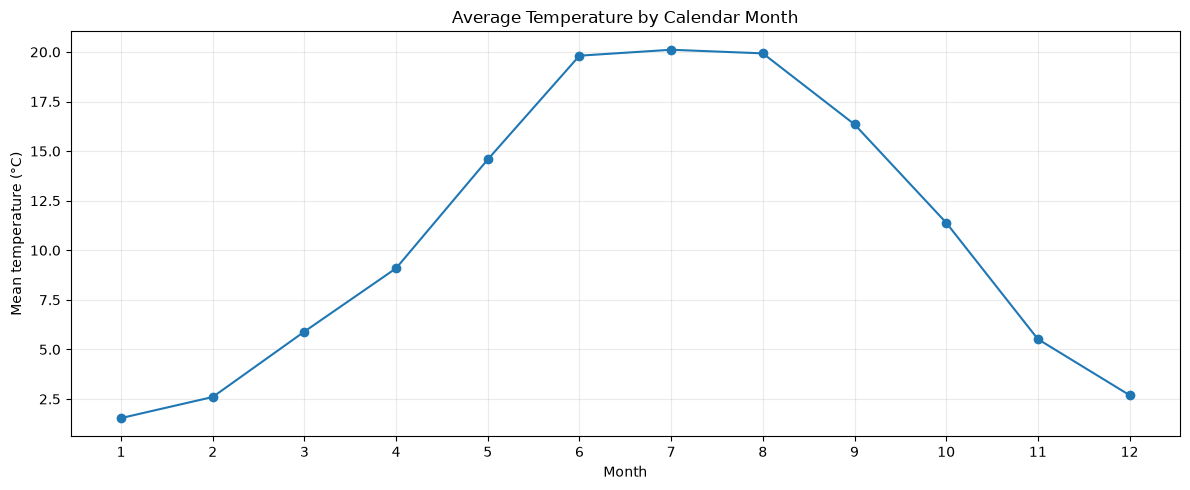

In [9]:
# 7. Exploratory visualisation

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_clean.index, df_clean["temp_mean"], linewidth=0.9)
ax.set_title("Berlin Daily Mean Temperature")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
monthly = df_clean.assign(month=df_clean.index.month).groupby("month")["temp_mean"].mean()
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Mean temperature (°C)")
ax.set_title("Average Temperature by Calendar Month")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# 8. Chronological train / validation / test split

The split is performed **before model evaluation** and respects temporal order.

- Training: earliest 70%
- Validation: following 15%
- Test: final 15%

The validation period is used for model selection and hyperparameter tuning.

The final rolling-origin test is never used to select hyperparameters.

In [10]:
n = len(df_clean)

train_end_idx = int(n * TRAIN_RATIO) - 1
val_end_idx = int(n * (TRAIN_RATIO + VALIDATION_RATIO)) - 1

train_end_date = df_clean.index[train_end_idx]
val_end_date = df_clean.index[val_end_idx]
test_start_date = df_clean.index[val_end_idx + 1]
test_end_date = df_clean.index[-1]

print("Training end:   ", train_end_date.date())
print("Validation end: ", val_end_date.date())
print("Test start:     ", test_start_date.date())
print("Test end:       ", test_end_date.date())

print("\nApproximate raw observations:")
print("Train:", train_end_idx + 1)
print("Validation:", val_end_idx - train_end_idx)
print("Test:", n - val_end_idx - 1)


Training end:    2024-12-18
Validation end:  2025-10-24
Test start:      2025-10-25
Test end:        2026-08-31

Approximate raw observations:
Train: 1448
Validation: 310
Test: 311


# 9. Calendar features

Calendar variables are deterministic and known at forecast time.

We use annual cyclic encoding rather than separate month dummy variables:

- `day_of_year_sin`
- `day_of_year_cos`

No future weather measurement is used as a model input.

In [11]:
def add_calendar_features(frame):
    out = frame.copy()
    day_of_year = out.index.dayofyear
    out["day_of_year_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    out["day_of_year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    return out


# Initial scaler: fitted ONLY on the training period.
train_raw = df_clean.loc[:train_end_date]

feature_scaler = MinMaxScaler()
feature_scaler.fit(train_raw[METEO_FEATURES])

target_scaler = MinMaxScaler()
target_scaler.fit(train_raw[[TARGET]])

scaled_meteo = pd.DataFrame(
    feature_scaler.transform(df_clean[METEO_FEATURES]),
    columns=METEO_FEATURES,
    index=df_clean.index,
)

features_all = add_calendar_features(scaled_meteo)

target_all_scaled = pd.Series(
    target_scaler.transform(df_clean[[TARGET]]).ravel(),
    index=df_clean.index,
    name=TARGET,
)

print("Scaler fitted on:", train_raw.index.min().date(), "to", train_raw.index.max().date())
print("Number of model input features:", features_all.shape[1])


Scaler fitted on: 2021-01-01 to 2024-12-18
Number of model input features: 12


# 10. Direct multi-step sequence construction

Each sample is:

**30 observed days → 7 future daily mean temperatures**

This is the key difference from V1.

The model is not trained for one-step prediction and then recursively fed its own predictions during evaluation.

For each sequence, we record:

- forecast origin
- first target date
- last target date

This lets us enforce clean temporal partitions.

In [12]:
def make_sequences(feature_frame, target_series, lookback=LOOKBACK, horizon=HORIZON):
    X, y = [], []
    origins, target_starts, target_ends = [], [], []

    values = feature_frame.values
    target_values = target_series.values
    dates = feature_frame.index

    for end_idx in range(lookback, len(feature_frame) - horizon + 1):
        X.append(values[end_idx - lookback:end_idx])
        y.append(target_values[end_idx:end_idx + horizon])

        origins.append(dates[end_idx - 1])
        target_starts.append(dates[end_idx])
        target_ends.append(dates[end_idx + horizon - 1])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        pd.DatetimeIndex(origins),
        pd.DatetimeIndex(target_starts),
        pd.DatetimeIndex(target_ends),
    )


X_all, y_all, origins_all, target_starts_all, target_ends_all = make_sequences(
    features_all, target_all_scaled
)

train_mask = target_ends_all <= train_end_date
val_mask = (
    (target_starts_all > train_end_date)
    & (target_ends_all <= val_end_date)
)
test_mask = target_starts_all > val_end_date

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_val = X_all[val_mask]
y_val = y_all[val_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

test_origins = origins_all[test_mask]

print("All sequences:", X_all.shape, y_all.shape)
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Test origins:", test_origins.min().date(), "to", test_origins.max().date())


All sequences: (2033, 30, 12) (2033, 7)
Train: (1412, 30, 12) (1412, 7)
Validation: (304, 30, 12) (304, 7)
Test: (305, 30, 12) (305, 7)
Test origins: 2025-10-24 to 2026-08-24


In [13]:
# 11. Utility functions for inverse transformation and metrics

def inverse_targets(y_scaled, scaler):
    arr = np.asarray(y_scaled)
    original_shape = arr.shape
    return scaler.inverse_transform(arr.reshape(-1, 1)).reshape(original_shape)


def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(
        2.0 * np.abs(y_pred - y_true)
        / (np.abs(y_true) + np.abs(y_pred) + eps)
    ) * 100.0


def mase(y_true, y_pred, training_series):
    scale = np.mean(np.abs(np.diff(np.asarray(training_series))))
    if scale == 0:
        return np.nan
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / scale


def horizon_metrics(y_true, y_pred, mase_scale_series=None):
    rows = []
    for h in range(y_true.shape[1]):
        yt = y_true[:, h]
        yp = y_pred[:, h]

        row = {
            "horizon": h + 1,
            "MAE": mean_absolute_error(yt, yp),
            "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "R2": r2_score(yt, yp),
            "sMAPE": smape(yt, yp),
        }

        if mase_scale_series is not None:
            row["MASE"] = mase(yt, yp, mase_scale_series)

        rows.append(row)

    return pd.DataFrame(rows)


def overall_metrics(y_true, y_pred, mase_scale_series=None):
    yt = np.asarray(y_true).ravel()
    yp = np.asarray(y_pred).ravel()

    result = {
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "R2": r2_score(yt, yp),
        "sMAPE": smape(yt, yp),
    }

    if mase_scale_series is not None:
        result["MASE"] = mase(yt, yp, mase_scale_series)

    return pd.Series(result)


train_temperature_reference = df_clean.loc[:val_end_date, TARGET].values


# 12. Naive baselines

These are essential because a sophisticated model should demonstrate improvement over simple forecasting rules.

### Persistence

For every horizon:

> forecast = most recently observed temperature

### Weekly seasonal naive

For horizon h:

> forecast(t+h) = observed temperature(t+h−7)

For a 1–7 day forecast, this uses only observations already available at the forecast origin.

In [14]:
def persistence_forecast(origin, frame=df_clean, horizon=HORIZON):
    last_value = frame.loc[origin, TARGET]
    return np.repeat(last_value, horizon)


def seasonal_naive_forecast(origin, frame=df_clean, horizon=HORIZON, seasonal_period=7):
    values = []
    for h in range(1, horizon + 1):
        target_date = origin + timedelta(days=h)
        reference_date = target_date - timedelta(days=seasonal_period)
        values.append(frame.loc[reference_date, TARGET])
    return np.asarray(values)


# Baseline evaluation on the test origins already available in the test split.
baseline_records = []

for origin in test_origins:
    actual_dates = [origin + timedelta(days=h) for h in range(1, HORIZON + 1)]
    actual = df_clean.loc[actual_dates, TARGET].values

    for model_name, pred in [
        ("Persistence", persistence_forecast(origin)),
        ("SeasonalNaive7", seasonal_naive_forecast(origin)),
    ]:
        for h, (actual_value, pred_value) in enumerate(zip(actual, pred), start=1):
            baseline_records.append({
                "origin": origin,
                "horizon": h,
                "model": model_name,
                "actual": actual_value,
                "prediction": pred_value,
            })

baseline_long = pd.DataFrame(baseline_records)

baseline_summary = (
    baseline_long
    .groupby(["model", "horizon"])
    .apply(lambda g: pd.Series({
        "MAE": mean_absolute_error(g["actual"], g["prediction"]),
        "RMSE": np.sqrt(mean_squared_error(g["actual"], g["prediction"])),
    }))
    .reset_index()
)

display(baseline_summary)


,model,horizon,MAE,RMSE
0,Persistence,1,1.793443,2.309780
1,Persistence,2,2.853770,3.602212
2,Persistence,3,3.437377,4.298662
3,Persistence,4,3.773443,4.710689
4,Persistence,5,4.052459,4.980414
5,Persistence,6,4.305902,5.278111
6,Persistence,7,4.574098,5.554260
7,SeasonalNaive7,1,4.544262,5.532770
8,SeasonalNaive7,2,4.540656,5.531629
9,SeasonalNaive7,3,4.537377,5.530147


# 13. Transformer components

In [15]:
def positional_encoding(length, depth):
    positions = np.arange(length)[:, None]
    dimensions = np.arange(depth)[None, :]

    angle_rates = 1 / np.power(
        10000,
        (2 * (dimensions // 2)) / np.float32(depth)
    )
    angle_rads = positions * angle_rates

    encoding = np.zeros((length, depth), dtype=np.float32)
    encoding[:, 0::2] = np.sin(angle_rads[:, 0::2])
    encoding[:, 1::2] = np.cos(angle_rads[:, 1::2])

    return tf.constant(encoding[None, :, :], dtype=tf.float32)


def transformer_block(x, model_dim, num_heads, ff_dim, dropout_rate):
    key_dim = model_dim // num_heads

    # Pre-norm self-attention
    attn_input = LayerNormalization(epsilon=1e-6)(x)
    attn_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout_rate,
    )(attn_input, attn_input)

    x = Add()([x, Dropout(dropout_rate)(attn_output)])

    # Pre-norm feed-forward block
    ff_input = LayerNormalization(epsilon=1e-6)(x)
    ff_output = Dense(ff_dim, activation="gelu")(ff_input)
    ff_output = Dropout(dropout_rate)(ff_output)
    ff_output = Dense(model_dim)(ff_output)

    return Add()([x, Dropout(dropout_rate)(ff_output)])


# 14. Model builders

Both neural architectures produce **seven outputs**.

That means the learning problem is explicitly:

**past 30 days → [t+1, t+2, ..., t+7]**

In [16]:
def build_bilstm(
    n_features,
    horizon=HORIZON,
    lstm1_units=64,
    lstm2_units=32,
    dropout_rate=0.2,
    dense_units=32,
    learning_rate=1e-3,
):
    inputs = Input(shape=(LOOKBACK, n_features))

    x = Bidirectional(
        LSTM(lstm1_units, return_sequences=True)
    )(inputs)
    x = Dropout(dropout_rate)(x)

    x = LSTM(lstm2_units, return_sequences=False)(x)
    x = Dropout(dropout_rate)(x)

    x = Dense(dense_units, activation="relu")(x)
    outputs = Dense(horizon)(x)

    model = Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"],
    )
    return model


def build_transformer(
    n_features,
    horizon=HORIZON,
    model_dim=64,
    num_heads=4,
    ff_dim=128,
    num_blocks=2,
    dropout_rate=0.1,
    dense_units=64,
    learning_rate=1e-3,
):
    assert model_dim % num_heads == 0

    inputs = Input(shape=(LOOKBACK, n_features))

    x = Dense(model_dim)(inputs)
    x = x + positional_encoding(LOOKBACK, model_dim)
    x = Dropout(dropout_rate)(x)

    for _ in range(num_blocks):
        x = transformer_block(
            x,
            model_dim=model_dim,
            num_heads=num_heads,
            ff_dim=ff_dim,
            dropout_rate=dropout_rate,
        )

    x = LayerNormalization(epsilon=1e-6)(x)
    x = GlobalAveragePooling1D()(x)
    x = Dense(dense_units, activation="relu")(x)
    x = Dropout(dropout_rate)(x)
    outputs = Dense(horizon)(x)

    model = Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"],
    )
    return model


# 15. Default-model validation benchmark

Before tuning, we train a fixed reasonable configuration for each neural model.

This creates a direct **default vs tuned** comparison on the validation period, which is required to answer the research question about whether tuning improves performance.

In [17]:
N_FEATURES = X_train.shape[-1]

DEFAULT_LSTM_CONFIG = {
    "lstm1_units": 64,
    "lstm2_units": 32,
    "dropout_rate": 0.2,
    "dense_units": 32,
    "learning_rate": 1e-3,
}

DEFAULT_TRANSFORMER_CONFIG = {
    "model_dim": 64,
    "num_heads": 4,
    "ff_dim": 128,
    "num_blocks": 2,
    "dropout_rate": 0.1,
    "dense_units": 64,
    "learning_rate": 1e-3,
}

def train_with_early_stopping(model, Xtr, ytr, Xv, yv, epochs=30):
    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True,
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
        ),
    ]

    history = model.fit(
        Xtr, ytr,
        validation_data=(Xv, yv),
        epochs=epochs,
        batch_size=32,
        shuffle=False,
        callbacks=callbacks,
        verbose=0,
    )
    return history


default_lstm = build_bilstm(N_FEATURES, **DEFAULT_LSTM_CONFIG)
default_lstm_history = train_with_early_stopping(
    default_lstm, X_train, y_train, X_val, y_val
)

default_transformer = build_transformer(
    N_FEATURES, **DEFAULT_TRANSFORMER_CONFIG
)
default_transformer_history = train_with_early_stopping(
    default_transformer, X_train, y_train, X_val, y_val
)

default_lstm_val = inverse_targets(
    default_lstm.predict(X_val, verbose=0), target_scaler
)
default_transformer_val = inverse_targets(
    default_transformer.predict(X_val, verbose=0), target_scaler
)
y_val_actual = inverse_targets(y_val, target_scaler)

default_validation_results = pd.DataFrame({
    "Model": ["Default BiLSTM", "Default Transformer"],
    "MAE": [
        mean_absolute_error(y_val_actual.ravel(), default_lstm_val.ravel()),
        mean_absolute_error(y_val_actual.ravel(), default_transformer_val.ravel()),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val_actual.ravel(), default_lstm_val.ravel())),
        np.sqrt(mean_squared_error(y_val_actual.ravel(), default_transformer_val.ravel())),
    ],
    "R2": [
        r2_score(y_val_actual.ravel(), default_lstm_val.ravel()),
        r2_score(y_val_actual.ravel(), default_transformer_val.ravel()),
    ],
})

display(default_validation_results)


E0000 00:00:1790067797.585488 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790067828.291707 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,Model,MAE,RMSE,R2
0,Default BiLSTM,2.510545,3.182640,0.817979
1,Default Transformer,2.522536,3.214573,0.814308


# 16. Hyperparameter tuning — BiLSTM

The validation set is the only dataset used for hyperparameter selection.

The test set is not touched here.

In [18]:
def bilstm_tuner_builder(hp):
    return build_bilstm(
        N_FEATURES,
        lstm1_units=hp.Choice("lstm1_units", [32, 64, 128]),
        lstm2_units=hp.Choice("lstm2_units", [16, 32, 64]),
        dropout_rate=hp.Choice("dropout_rate", [0.1, 0.2, 0.3]),
        dense_units=hp.Choice("dense_units", [16, 32, 64]),
        learning_rate=hp.Choice("learning_rate", [1e-3, 5e-4, 1e-4]),
    )


if RUN_TUNING:
    lstm_tuner = kt.RandomSearch(
        bilstm_tuner_builder,
        objective="val_loss",
        max_trials=LSTM_MAX_TRIALS,
        overwrite=True,
        directory="v2_tuner",
        project_name="bilstm_7day",
    )

    lstm_tuner.search(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=TUNER_MAX_EPOCHS,
        batch_size=32,
        shuffle=False,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True,
            )
        ],
        verbose=0,
    )

    best_lstm_hp = lstm_tuner.get_best_hyperparameters(1)[0]
    best_lstm_config = {
        "lstm1_units": best_lstm_hp.get("lstm1_units"),
        "lstm2_units": best_lstm_hp.get("lstm2_units"),
        "dropout_rate": best_lstm_hp.get("dropout_rate"),
        "dense_units": best_lstm_hp.get("dense_units"),
        "learning_rate": best_lstm_hp.get("learning_rate"),
    }

    best_lstm_trial = lstm_tuner.oracle.get_best_trials(1)[0]
    try:
        best_lstm_epochs = int(
            best_lstm_trial.metrics.get_best_step("val_loss")
        ) + 1
    except Exception:
        best_lstm_epochs = TUNER_MAX_EPOCHS
else:
    best_lstm_config = DEFAULT_LSTM_CONFIG.copy()
    best_lstm_epochs = 20

print("Best BiLSTM configuration:")
print(best_lstm_config)
print("Selected training epochs:", best_lstm_epochs)


E0000 00:00:1790067849.549798 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790067873.048749 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best BiLSTM configuration:
{'lstm1_units': 128, 'lstm2_units': 64, 'dropout_rate': 0.3, 'dense_units': 16, 'learning_rate': 0.0005}
Selected training epochs: 12


# 17. Hyperparameter tuning — Transformer

In [19]:
def transformer_tuner_builder(hp):
    model_dim = hp.Choice("model_dim", [32, 64, 96])
    num_heads = hp.Choice("num_heads", [2, 4, 8])

    return build_transformer(
        N_FEATURES,
        model_dim=model_dim,
        num_heads=num_heads,
        ff_dim=hp.Choice("ff_dim", [64, 128, 192]),
        num_blocks=hp.Choice("num_blocks", [1, 2, 3]),
        dropout_rate=hp.Choice("dropout_rate", [0.05, 0.1, 0.2]),
        dense_units=hp.Choice("dense_units", [32, 64, 96]),
        learning_rate=hp.Choice("learning_rate", [1e-3, 5e-4, 1e-4]),
    )


if RUN_TUNING:
    transformer_tuner = kt.RandomSearch(
        transformer_tuner_builder,
        objective="val_loss",
        max_trials=TRANSFORMER_MAX_TRIALS,
        overwrite=True,
        directory="v2_tuner",
        project_name="transformer_7day",
    )

    transformer_tuner.search(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=TUNER_MAX_EPOCHS,
        batch_size=32,
        shuffle=False,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True,
            )
        ],
        verbose=0,
    )

    best_transformer_hp = transformer_tuner.get_best_hyperparameters(1)[0]
    best_transformer_config = {
        "model_dim": best_transformer_hp.get("model_dim"),
        "num_heads": best_transformer_hp.get("num_heads"),
        "ff_dim": best_transformer_hp.get("ff_dim"),
        "num_blocks": best_transformer_hp.get("num_blocks"),
        "dropout_rate": best_transformer_hp.get("dropout_rate"),
        "dense_units": best_transformer_hp.get("dense_units"),
        "learning_rate": best_transformer_hp.get("learning_rate"),
    }

    best_transformer_trial = transformer_tuner.oracle.get_best_trials(1)[0]
    try:
        best_transformer_epochs = int(
            best_transformer_trial.metrics.get_best_step("val_loss")
        ) + 1
    except Exception:
        best_transformer_epochs = TUNER_MAX_EPOCHS
else:
    best_transformer_config = DEFAULT_TRANSFORMER_CONFIG.copy()
    best_transformer_epochs = 20

print("Best Transformer configuration:")
print(best_transformer_config)
print("Selected training epochs:", best_transformer_epochs)


E0000 00:00:1790067987.522899 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790068001.984809 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best Transformer configuration:
{'model_dim': 64, 'num_heads': 2, 'ff_dim': 192, 'num_blocks': 2, 'dropout_rate': 0.1, 'dense_units': 96, 'learning_rate': 0.0005}
Selected training epochs: 9


# 18. Tuned vs default validation comparison

This comparison is performed before the final test evaluation.

It directly addresses:

> **Does hyperparameter tuning improve predictive performance?**

In [20]:
tuned_lstm = build_bilstm(N_FEATURES, **best_lstm_config)
tuned_lstm_history = train_with_early_stopping(
    tuned_lstm, X_train, y_train, X_val, y_val,
    epochs=max(best_lstm_epochs, 10)
)

tuned_transformer = build_transformer(
    N_FEATURES, **best_transformer_config
)
tuned_transformer_history = train_with_early_stopping(
    tuned_transformer, X_train, y_train, X_val, y_val,
    epochs=max(best_transformer_epochs, 10)
)

tuned_lstm_val = inverse_targets(
    tuned_lstm.predict(X_val, verbose=0), target_scaler
)
tuned_transformer_val = inverse_targets(
    tuned_transformer.predict(X_val, verbose=0), target_scaler
)

tuning_comparison = pd.DataFrame([
    {
        "Model": "Default BiLSTM",
        **overall_metrics(y_val_actual, default_lstm_val),
    },
    {
        "Model": "Tuned BiLSTM",
        **overall_metrics(y_val_actual, tuned_lstm_val),
    },
    {
        "Model": "Default Transformer",
        **overall_metrics(y_val_actual, default_transformer_val),
    },
    {
        "Model": "Tuned Transformer",
        **overall_metrics(y_val_actual, tuned_transformer_val),
    },
])

display(tuning_comparison.round(4))


E0000 00:00:1790068134.516582 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790068192.690280 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,Model,MAE,RMSE,R2,sMAPE
0,Default BiLSTM,2.5105,3.1826,0.8180,40.0892
1,Tuned BiLSTM,2.4971,3.1412,0.8227,40.9368
2,Default Transformer,2.5225,3.2146,0.8143,41.4960
3,Tuned Transformer,2.5965,3.3185,0.8021,42.4345


# 19. Prophet hyperparameter tuning

Prophet is tuned on validation forecast origins only.

Crucially, **future meteorological regressors are not supplied**.

The Prophet comparison therefore uses the same information class as the historical-only neural forecasting task:

- past target temperature
- known calendar dates
- learned trend/seasonality

No future humidity, radiation, precipitation or wind values are used.

In [21]:
PROPHET_PARAM_SPACE = {
    "changepoint_prior_scale": [0.01, 0.05, 0.1, 0.5],
    "seasonality_prior_scale": [0.1, 1.0, 5.0, 10.0],
    "seasonality_mode": ["additive", "multiplicative"],
    "changepoint_range": [0.8, 0.9],
}

def fit_prophet(train_frame, params):
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        **params,
    )
    prophet_train = (
        train_frame[[TARGET]]
        .reset_index()
        .rename(columns={"date": "ds", TARGET: "y"})
    )
    model.fit(prophet_train)
    return model


# Choose three validation origins with a full 7-day future available.
validation_candidates = df_clean.index[
    (df_clean.index > train_end_date)
    & (df_clean.index + pd.Timedelta(days=HORIZON) <= val_end_date)
]

if len(validation_candidates) > 0:
    idxs = np.linspace(
        0, len(validation_candidates) - 1,
        min(3, len(validation_candidates)),
        dtype=int
    )
    prophet_val_origins = pd.DatetimeIndex(
        validation_candidates[np.unique(idxs)]
    )
else:
    prophet_val_origins = pd.DatetimeIndex([])

print("Prophet validation origins:")
for d in prophet_val_origins:
    print(" ", d.date())


Prophet validation origins:
  2024-12-19
  2025-05-19
  2025-10-17


In [22]:
import itertools

def sample_prophet_configs(param_space, n=12, seed=SEED):
    all_configs = [
        dict(zip(param_space.keys(), values))
        for values in itertools.product(*param_space.values())
    ]

    rng = np.random.default_rng(seed)
    if n >= len(all_configs):
        return all_configs

    chosen = rng.choice(len(all_configs), size=n, replace=False)
    return [all_configs[i] for i in chosen]


prophet_configs = sample_prophet_configs(PROPHET_PARAM_SPACE, n=12)

prophet_tuning_rows = []

for config_id, params in enumerate(prophet_configs, start=1):
    fold_errors = []

    for origin in prophet_val_origins:
        train_frame = df_clean.loc[:origin]
        actual_dates = [origin + timedelta(days=h) for h in range(1, HORIZON + 1)]
        actual = df_clean.loc[actual_dates, TARGET].values

        model = fit_prophet(train_frame, params)

        future = pd.DataFrame({"ds": pd.to_datetime(actual_dates)})
        pred = model.predict(future)["yhat"].values

        fold_errors.append(mean_absolute_error(actual, pred))

    prophet_tuning_rows.append({
        "config_id": config_id,
        **params,
        "validation_MAE": np.mean(fold_errors),
    })

prophet_tuning_results = pd.DataFrame(prophet_tuning_rows).sort_values(
    "validation_MAE"
)

best_prophet_row = prophet_tuning_results.iloc[0]
best_prophet_config = {
    key: best_prophet_row[key]
    for key in PROPHET_PARAM_SPACE.keys()
}

display(prophet_tuning_results.head(10))
print("\nSelected Prophet configuration:")
print(best_prophet_config)


11:10:04 - cmdstanpy - INFO - Chain [1] start processing
11:10:06 - cmdstanpy - INFO - Chain [1] done processing
11:10:06 - cmdstanpy - INFO - Chain [1] start processing
11:10:06 - cmdstanpy - INFO - Chain [1] done processing
11:10:06 - cmdstanpy - INFO - Chain [1] start processing
11:10:06 - cmdstanpy - INFO - Chain [1] done processing
11:10:06 - cmdstanpy - INFO - Chain [1] start processing
11:10:06 - cmdstanpy - INFO - Chain [1] done processing
11:10:06 - cmdstanpy - INFO - Chain [1] start processing
11:10:06 - cmdstanpy - INFO - Chain [1] done processing
11:10:07 - cmdstanpy - INFO - Chain [1] start processing
11:10:07 - cmdstanpy - INFO - Chain [1] done processing
11:10:07 - cmdstanpy - INFO - Chain [1] start processing
11:10:07 - cmdstanpy - INFO - Chain [1] done processing
11:10:07 - cmdstanpy - INFO - Chain [1] start processing
11:10:07 - cmdstanpy - INFO - Chain [1] done processing
11:10:07 - cmdstanpy - INFO - Chain [1] start processing
11:10:07 - cmdstanpy - INFO - Chain [1]

,config_id,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,changepoint_range,validation_MAE
4,5,0.10,1.0,additive,0.8,2.125609
3,4,0.10,0.1,additive,0.9,2.126431
7,8,0.50,5.0,additive,0.8,2.136152
2,3,0.10,5.0,additive,0.9,2.137014
0,1,0.05,5.0,additive,0.8,2.144401
10,11,0.50,10.0,multiplicative,0.8,2.158276
9,10,0.50,5.0,multiplicative,0.9,2.177017
5,6,0.50,0.1,additive,0.9,2.187870
8,9,0.50,10.0,additive,0.9,2.199085
1,2,0.01,1.0,additive,0.9,2.262304



Selected Prophet configuration:
{'changepoint_prior_scale': np.float64(0.1), 'seasonality_prior_scale': np.float64(1.0), 'seasonality_mode': 'additive', 'changepoint_range': np.float64(0.8)}


# 20. Rolling-origin test design

The final evaluation uses several origins from the untouched test period.

For every origin, the models forecast the same next seven calendar days.

This produces a collection of genuine 1–7 day forecasts instead of treating a long test period as one giant multi-week forecast.

In [23]:
test_origin_candidates = df_clean.index[
    (df_clean.index > val_end_date)
    & (df_clean.index + pd.Timedelta(days=HORIZON) <= test_end_date)
]

if len(test_origin_candidates) < N_ROLLING_ORIGINS:
    selected_test_origins = pd.DatetimeIndex(test_origin_candidates)
else:
    idxs = np.linspace(
        0, len(test_origin_candidates) - 1,
        N_ROLLING_ORIGINS,
        dtype=int
    )
    selected_test_origins = pd.DatetimeIndex(
        test_origin_candidates[np.unique(idxs)]
    )

print("Selected final test forecast origins:")
for d in selected_test_origins:
    print(" ", d.date())


Selected final test forecast origins:
  2025-10-25
  2025-12-24
  2026-02-23
  2026-04-24
  2026-06-24
  2026-08-24


# 21. Rolling-origin model utilities

For each final test origin, the neural networks are retrained using only data available at that origin.

The previously selected hyperparameters are kept fixed.

This avoids using the test period to tune architecture choices while still allowing the model to learn from newly available historical observations.

In [24]:
def build_scaled_history_until(origin):
    available = df_clean.loc[:origin].copy()

    scaler_x = MinMaxScaler()
    scaler_x.fit(available[METEO_FEATURES])

    scaler_y = MinMaxScaler()
    scaler_y.fit(available[[TARGET]])

    scaled = pd.DataFrame(
        scaler_x.transform(available[METEO_FEATURES]),
        columns=METEO_FEATURES,
        index=available.index,
    )

    featured = add_calendar_features(scaled)

    target_scaled = pd.Series(
        scaler_y.transform(available[[TARGET]]).ravel(),
        index=available.index,
        name=TARGET,
    )

    return available, scaler_x, scaler_y, featured, target_scaled


def train_predict_bilstm_at_origin(origin):
    available, scaler_x, scaler_y, featured, target_scaled = (
        build_scaled_history_until(origin)
    )

    X_seq, y_seq, _, _, _ = make_sequences(
        featured, target_scaled, LOOKBACK, HORIZON
    )

    model = build_bilstm(
        X_seq.shape[-1],
        **best_lstm_config
    )

    model.fit(
        X_seq, y_seq,
        epochs=max(best_lstm_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    last_sequence = featured.iloc[-LOOKBACK:].values.astype(np.float32)
    pred_scaled = model.predict(
        last_sequence[None, :, :], verbose=0
    )[0]

    prediction = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    return prediction


def train_predict_transformer_at_origin(origin):
    available, scaler_x, scaler_y, featured, target_scaled = (
        build_scaled_history_until(origin)
    )

    X_seq, y_seq, _, _, _ = make_sequences(
        featured, target_scaled, LOOKBACK, HORIZON
    )

    model = build_transformer(
        X_seq.shape[-1],
        **best_transformer_config
    )

    model.fit(
        X_seq, y_seq,
        epochs=max(best_transformer_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    last_sequence = featured.iloc[-LOOKBACK:].values.astype(np.float32)
    pred_scaled = model.predict(
        last_sequence[None, :, :], verbose=0
    )[0]

    prediction = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    return prediction


def prophet_predict_at_origin(origin):
    available = df_clean.loc[:origin]

    model = fit_prophet(
        available,
        best_prophet_config
    )

    future_dates = [
        origin + timedelta(days=h)
        for h in range(1, HORIZON + 1)
    ]

    future = pd.DataFrame({"ds": pd.to_datetime(future_dates)})
    return model.predict(future)["yhat"].values


# 22. Run the final rolling-origin evaluation

This is the most computationally expensive section.

The test period is untouched until this point.

In [25]:
rolling_records = []

if RUN_ROLLING_EVALUATION:
    for origin_number, origin in enumerate(selected_test_origins, start=1):
        print(
            f"[{origin_number}/{len(selected_test_origins)}] "
            f"Forecast origin: {origin.date()}"
        )

        actual_dates = [
            origin + timedelta(days=h)
            for h in range(1, HORIZON + 1)
        ]
        actual = df_clean.loc[actual_dates, TARGET].values

        predictions = {
            "Persistence": persistence_forecast(origin),
            "SeasonalNaive7": seasonal_naive_forecast(origin),
            "Prophet": prophet_predict_at_origin(origin),
            "BiLSTM": train_predict_bilstm_at_origin(origin),
            "Transformer": train_predict_transformer_at_origin(origin),
        }

        for model_name, pred in predictions.items():
            for h, (actual_value, pred_value) in enumerate(
                zip(actual, pred), start=1
            ):
                rolling_records.append({
                    "origin": origin,
                    "target_date": actual_dates[h - 1],
                    "horizon": h,
                    "model": model_name,
                    "actual": actual_value,
                    "prediction": pred_value,
                    "error": pred_value - actual_value,
                    "absolute_error": abs(pred_value - actual_value),
                })

    rolling_results = pd.DataFrame(rolling_records)
    rolling_results.to_csv("v2_rolling_predictions.csv", index=False)

    print("\nSaved: v2_rolling_predictions.csv")
else:
    rolling_results = pd.DataFrame()
    print("Rolling evaluation disabled.")


11:10:12 - cmdstanpy - INFO - Chain [1] start processing
11:10:12 - cmdstanpy - INFO - Chain [1] done processing


[1/6] Forecast origin: 2025-10-25


E0000 00:00:1790068212.315808 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1790068532.807416 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

[2/6] Forecast origin: 2025-12-24


E0000 00:00:1790068573.969523 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1790068872.984966 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


... (7 outputs left out)

[6/6] Forecast origin: 2026-08-24


E0000 00:00:1790069456.132345 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



Saved: v2_rolling_predictions.csv


E0000 00:00:1790069468.921379 4936174 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


# 23. Final horizon-by-horizon comparison

The key thesis table should be based on this output.

The table answers:

> How does forecasting error change from day 1 through day 7?

Do not collapse the entire problem into one overall score.

In [26]:
if not rolling_results.empty:
    horizon_table = (
        rolling_results
        .groupby(["model", "horizon"])
        .apply(lambda g: pd.Series({
            "MAE": mean_absolute_error(g["actual"], g["prediction"]),
            "RMSE": np.sqrt(mean_squared_error(g["actual"], g["prediction"])),
            "R2": r2_score(g["actual"], g["prediction"]),
            "sMAPE": smape(g["actual"], g["prediction"]),
            "MASE": mase(g["actual"], g["prediction"], train_temperature_reference),
        }))
        .reset_index()
    )

    display(
        horizon_table
        .pivot(index="horizon", columns="model", values="MAE")
        .round(3)
    )

    display(
        horizon_table
        .pivot(index="horizon", columns="model", values="RMSE")
        .round(3)
    )


model,BiLSTM,Persistence,Prophet,SeasonalNaive7,Transformer
horizon,,,,,
1,4.065,2.150,4.464,5.800,5.116
2,3.971,2.233,3.669,4.050,3.751
3,4.106,2.667,3.919,5.517,3.922
4,5.395,3.633,5.008,6.367,5.105
5,3.924,3.017,3.478,3.283,4.241
6,2.705,2.517,3.253,2.800,2.438
7,2.816,2.900,2.902,2.900,2.915


model,BiLSTM,Persistence,Prophet,SeasonalNaive7,Transformer
horizon,,,,,
1,5.260,2.565,5.858,6.855,6.200
2,4.699,2.344,4.791,5.551,4.697
3,4.999,3.668,5.418,6.374,5.816
4,6.382,4.659,6.733,7.784,6.859
5,4.825,3.789,4.740,4.226,5.560
6,3.166,3.198,3.572,3.433,3.130
7,2.959,3.489,3.325,3.489,3.496


# 24. Overall test metrics

Use this table as a compact summary, but keep the horizon-specific table as the primary result.

In [27]:
if not rolling_results.empty:
    overall_rows = []

    for model_name, group in rolling_results.groupby("model"):
        overall_rows.append({
            "Model": model_name,
            "MAE": mean_absolute_error(
                group["actual"], group["prediction"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(group["actual"], group["prediction"])
            ),
            "R2": r2_score(group["actual"], group["prediction"]),
            "sMAPE": smape(
                group["actual"], group["prediction"]
            ),
"MASE": mase(
                group["actual"], group["prediction"], train_temperature_reference
            ),
        })

    overall_test_table = (
        pd.DataFrame(overall_rows)
        .sort_values("MAE")
        .reset_index(drop=True)
    )

    display(overall_test_table.round(4))


,Model,MAE,RMSE,R2,sMAPE,MASE
0,Persistence,2.7310,3.4641,0.8707,39.7053,1.6520
1,Prophet,3.8133,5.0461,0.7257,59.6221,2.3067
2,BiLSTM,3.8548,4.7437,0.7576,59.3413,2.3318
3,Transformer,3.9267,5.2686,0.7009,70.3506,2.3752
4,SeasonalNaive7,4.3881,5.6169,0.6601,65.4633,2.6544


# 25. Forecast-error growth with horizon

A strong thesis figure is the relationship between forecast horizon and error.

A useful interpretation is not simply "Model X wins", but:

- Does error increase with horizon?
- Which models degrade fastest?
- Do simple baselines remain competitive?
- Does the Transformer improve or deteriorate relative to recurrent forecasting as the horizon increases?

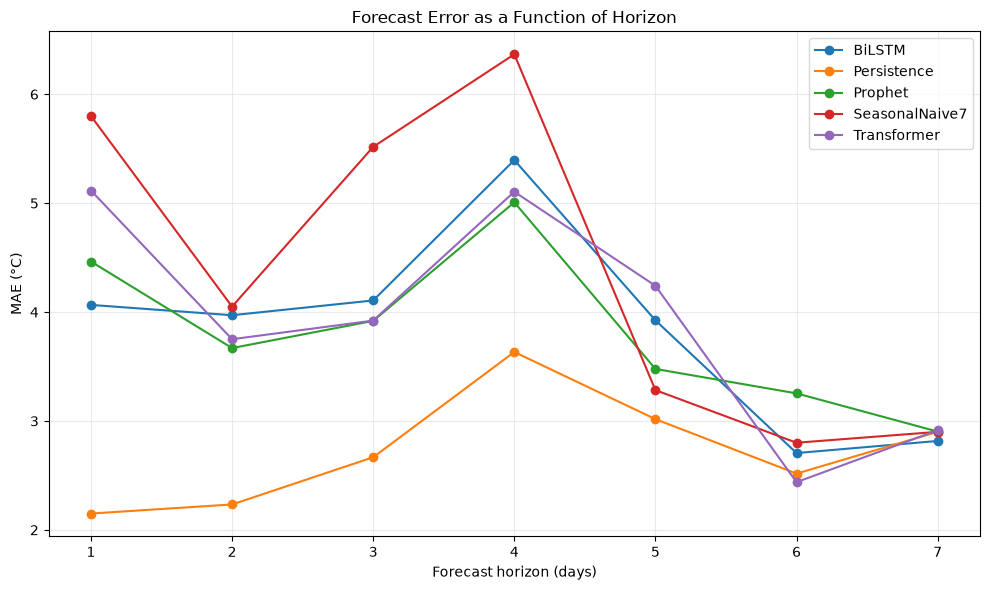

In [28]:
if not rolling_results.empty:
    fig, ax = plt.subplots(figsize=(10, 6))

    for model_name, group in rolling_results.groupby("model"):
        by_h = group.groupby("horizon")["absolute_error"].mean()
        ax.plot(by_h.index, by_h.values, marker="o", label=model_name)

    ax.set_xlabel("Forecast horizon (days)")
    ax.set_ylabel("MAE (°C)")
    ax.set_title("Forecast Error as a Function of Horizon")
    ax.set_xticks(range(1, HORIZON + 1))
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()


# 26. Prediction example from a final test origin

This visual is useful for the thesis because it shows a complete seven-day forecast rather than a sequence of one-step predictions.

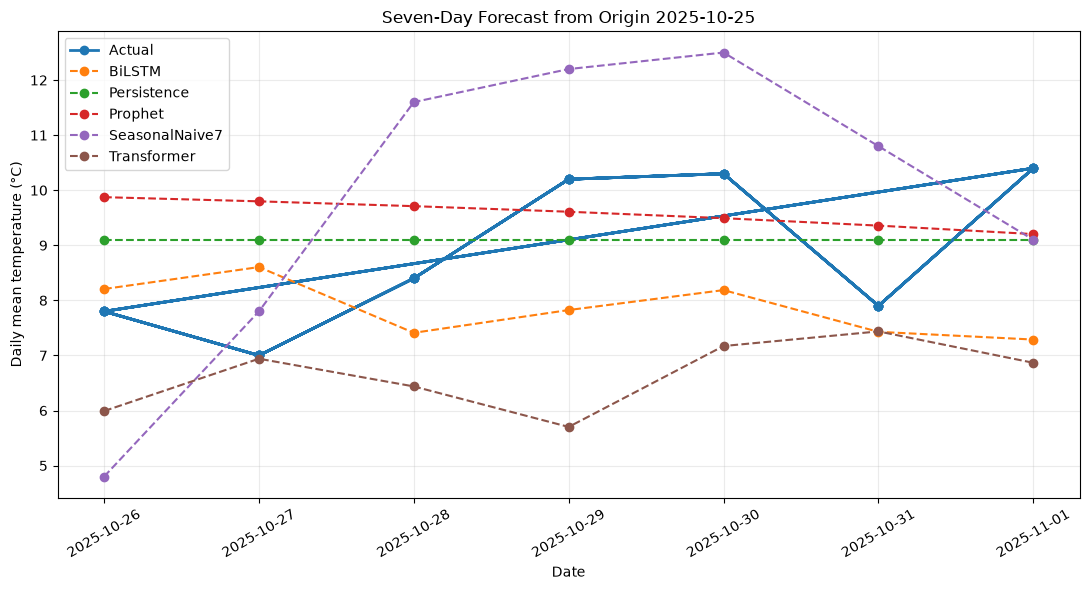

In [29]:
if not rolling_results.empty:
    example_origin = selected_test_origins[0]
    example = rolling_results[
        rolling_results["origin"] == example_origin
    ].copy()

    fig, ax = plt.subplots(figsize=(11, 6))

    actual_dates = pd.to_datetime(example["target_date"])
    ax.plot(
        actual_dates,
        example["actual"],
        marker="o",
        linewidth=2,
        label="Actual",
    )

    for model_name, group in example.groupby("model"):
        ax.plot(
            pd.to_datetime(group["target_date"]),
            group["prediction"],
            marker="o",
            linestyle="--",
            label=model_name,
        )

    ax.set_title(
        f"Seven-Day Forecast from Origin {example_origin.date()}"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("Daily mean temperature (°C)")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


# 27. Optional feature ablation — BiLSTM

This experiment can support a stronger thesis contribution:

> Does adding meteorological variables actually improve forecasting beyond historical temperature and calendar information?

The default is `RUN_FEATURE_ABLATION = False` because it adds training time.

If enabled, compare:

1. Temperature history + calendar features
2. All historical meteorological variables + calendar features

In [30]:
if RUN_FEATURE_ABLATION:
    print("Feature ablation is enabled.")
    print("Recommended interpretation: compare validation MAE/RMSE, not just training loss.")

    # Temperature-only feature set
    temp_feature_cols = ["temp_mean"]
    temp_scaler = MinMaxScaler()
    temp_scaler.fit(train_raw[temp_feature_cols])

    temp_scaled = pd.DataFrame(
        temp_scaler.transform(df_clean[temp_feature_cols]),
        columns=temp_feature_cols,
        index=df_clean.index,
    )
    temp_features = add_calendar_features(temp_scaled)

    temp_target_scaler = MinMaxScaler()
    temp_target_scaler.fit(train_raw[[TARGET]])
    temp_target_scaled = pd.Series(
        temp_target_scaler.transform(df_clean[[TARGET]]).ravel(),
        index=df_clean.index,
    )

    Xa, ya, _, tsa, tea = make_sequences(
        temp_features, temp_target_scaled
    )

    tr = tea <= train_end_date
    va = (tsa > train_end_date) & (tea <= val_end_date)

    ablation_model = build_bilstm(
        Xa.shape[-1],
        **best_lstm_config
    )
    ablation_model.fit(
        Xa[tr], ya[tr],
        validation_data=(Xa[va], ya[va]),
        epochs=max(best_lstm_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    ablation_pred = inverse_targets(
        ablation_model.predict(Xa[va], verbose=0),
        temp_target_scaler
    )
    ablation_true = inverse_targets(
        ya[va],
        temp_target_scaler
    )

    print("Temperature-history-only validation results:")
    print(
        overall_metrics(
            ablation_true,
            ablation_pred
        ).round(4)
    )
else:
    print("Feature ablation disabled.")


Feature ablation disabled.


# 28. Optional lookback-window sensitivity

The original thesis selected 30 days without a systematic sensitivity analysis.

If enabled, test several lookback values using the same validation protocol.

Suggested values:

- 7 days
- 14 days
- 30 days
- 60 days
- 90 days

This can become a useful methodological discussion point.

In [31]:
if RUN_LOOKBACK_ABLATION:
    LOOKBACK_VALUES = [7, 14, 30, 60, 90]
    print(
        "Lookback ablation requested. "
        "Run this as a separate experiment and record validation MAE/RMSE."
    )
    print("Lookback values:", LOOKBACK_VALUES)
else:
    print("Lookback ablation disabled.")


Lookback ablation disabled.


# 29. Optional live 7-day forecast

Unlike V1, the direct multi-output neural models do not need future humidity, radiation, precipitation, or wind values to produce the seven-day forecast.

The model consumes the latest 30 observed days and directly outputs seven temperatures.

For the thesis, record the exact data retrieval date/time alongside any live forecast.

In [32]:
def train_full_model_for_live_forecast():
    available = df_clean.copy()

    scaler_x = MinMaxScaler()
    scaler_x.fit(available[METEO_FEATURES])

    scaler_y = MinMaxScaler()
    scaler_y.fit(available[[TARGET]])

    scaled = pd.DataFrame(
        scaler_x.transform(available[METEO_FEATURES]),
        columns=METEO_FEATURES,
        index=available.index,
    )
    featured = add_calendar_features(scaled)

    target_scaled = pd.Series(
        scaler_y.transform(available[[TARGET]]).ravel(),
        index=available.index,
    )

    X_live, y_live, _, _, _ = make_sequences(
        featured, target_scaled
    )

    bilstm = build_bilstm(
        X_live.shape[-1],
        **best_lstm_config
    )
    bilstm.fit(
        X_live, y_live,
        epochs=max(best_lstm_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    transformer = build_transformer(
        X_live.shape[-1],
        **best_transformer_config
    )
    transformer.fit(
        X_live, y_live,
        epochs=max(best_transformer_epochs, 10),
        batch_size=32,
        shuffle=False,
        verbose=0,
    )

    prophet = fit_prophet(
        available,
        best_prophet_config
    )

    last_sequence = featured.iloc[-LOOKBACK:].values.astype(np.float32)

    lstm_scaled = bilstm.predict(
        last_sequence[None, :, :], verbose=0
    )[0]
    transformer_scaled = transformer.predict(
        last_sequence[None, :, :], verbose=0
    )[0]

    lstm_forecast = scaler_y.inverse_transform(
        lstm_scaled.reshape(-1, 1)
    ).ravel()

    transformer_forecast = scaler_y.inverse_transform(
        transformer_scaled.reshape(-1, 1)
    ).ravel()

    forecast_dates = [
        available.index[-1] + timedelta(days=h)
        for h in range(1, HORIZON + 1)
    ]

    prophet_forecast = prophet.predict(
        pd.DataFrame({"ds": pd.to_datetime(forecast_dates)})
    )["yhat"].values

    forecast_table = pd.DataFrame({
        "date": forecast_dates,
        "BiLSTM": lstm_forecast,
        "Transformer": transformer_forecast,
        "Prophet": prophet_forecast,
    })

    return forecast_table


if RUN_LIVE_FORECAST:
    live_forecast = train_full_model_for_live_forecast()
    display(live_forecast.round(2))
else:
    print("Live forecast disabled.")


Live forecast disabled.


# 30. Save thesis-ready outputs

Save the raw predictions and the principal result tables.

This is important because the thesis should be written from the actual V2 output rather than manually copied numbers.

In [33]:
config_to_save = {
    "seed": SEED,
    "city": CITY,
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "start_date": START_DATE,
    "end_date": END_DATE,
    "lookback": LOOKBACK,
    "horizon": HORIZON,
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VALIDATION_RATIO,
    "test_ratio": TEST_RATIO,
    "rolling_origins": [
        str(x.date()) for x in selected_test_origins
    ],
    "best_lstm_config": best_lstm_config,
    "best_lstm_epochs": best_lstm_epochs,
    "best_transformer_config": best_transformer_config,
    "best_transformer_epochs": best_transformer_epochs,
    "best_prophet_config": best_prophet_config,
}

with open("v2_config.json", "w") as f:
    json.dump(config_to_save, f, indent=2, default=str)

if not rolling_results.empty:
    horizon_table.to_csv("v2_horizon_metrics.csv", index=False)
    overall_test_table.to_csv("v2_overall_metrics.csv", index=False)

tuning_comparison.to_csv("v2_tuning_comparison.csv", index=False)

print("Saved V2 configuration and result tables.")


Saved V2 configuration and result tables.


# 31. What the thesis should report from V2

Do **not** write the conclusion before the notebook is run.

The final thesis results should contain at least:

### Table 1 — Dataset
- number of observations
- exact date range
- variables
- missing-value handling
- train/validation/test dates

### Table 2 — Hyperparameter tuning
- default vs tuned BiLSTM
- default vs tuned Transformer
- validation MAE/RMSE

### Table 3 — Final model configuration
- BiLSTM architecture
- Transformer architecture
- Prophet configuration

### Table 4 — Main forecasting results
For horizons 1–7:
- MAE
- RMSE
- R²
- sMAPE
- MASE

### Table 5 — Baseline comparison
- Persistence
- Seasonal naive
- Prophet
- BiLSTM
- Transformer

### Figures
1. Temperature series
2. Forecast error versus horizon
3. Seven-day forecast example
4. Actual vs predicted scatter or residual analysis
5. Optional ablation results

### Important interpretation rule

Do not state that one architecture is universally "best".

Instead describe:
- which model had lower error under this experimental protocol,
- at which horizons,
- by how much,
- whether the difference was consistent,
- and how the result depends on the Berlin dataset and experimental setup.

# 32. V2 checklist before submission

- [ ] Run the notebook from the first cell to the last.
- [ ] Keep the final data dates fixed.
- [ ] Confirm no scaler was fitted using test observations.
- [ ] Confirm no future meteorological regressors were used.
- [ ] Confirm all models predict the same seven target dates at each origin.
- [ ] Confirm the test period was not used for hyperparameter selection.
- [ ] Report horizon-specific errors.
- [ ] Report persistence and seasonal-naive baselines.
- [ ] Remove MAPE from the thesis.
- [ ] Explain the direct multi-output forecasting strategy.
- [ ] Explain the rolling-origin test protocol.
- [ ] Save `v2_config.json` and the CSV result tables.
- [ ] Rewrite the research gap around fair, leakage-controlled, horizon-specific comparison.
- [ ] Rewrite the conclusion only after seeing the V2 results.

## Central methodological claim

The strongest version of the thesis is no longer simply:

> "I compared LSTM, Transformer and Prophet."

It becomes:

> **"I developed a leakage-controlled, horizon-specific experimental framework to compare recurrent, attention-based, statistical, and naive forecasting approaches for 1–7 day daily mean temperature prediction in Berlin."**

The empirical results should determine the final conclusions.